# T-cell context responsiveness

Each prediction row is a query T cell paired with a sampled neighborhood. The same query appears in multiple contexts and sampling repeats. This notebook compares gene probabilities with the query's original neighborhood and visualizes how they vary with neighborhood cell-type composition. Composition slopes are descriptive associations; cell-type proportions sum to one.

In [339]:
from pathlib import Path
import anndata as ad
import numpy as np
import pandas as pd

PREDICTION_DIR = Path(
    "/work/magroup/skrieger/Syndri/data/datasets/"
    "breast_xenium/results/responsiveness/predictions"
)
PREDICTION_FILES = sorted(
    PREDICTION_DIR.glob("*_cd4_memory_responsiveness_predictions.h5ad")
)

if not PREDICTION_FILES:
    raise FileNotFoundError("No matching prediction files found")

datasets = []
for path in PREDICTION_FILES:
    tissue = path.name.removesuffix(
        "_cd4_memory_responsiveness_predictions.h5ad"
    )
    a = ad.read_h5ad(path)

    # Prevent cells from different tissues being grouped together.
    a.obs_names = pd.Index(tissue + "::" + a.obs_names.astype(str))
    a.obs["focal_cell_id"] = (
        tissue + "::" + a.obs["focal_cell_id"].astype(str)
    )
    a.obs["context_source_cell_id"] = (
        tissue + "::" + a.obs["context_source_cell_id"].astype(str)
    )
    a.obs["tissue"] = tissue
    datasets.append(a)

# A cell type absent from one tissue has proportion zero there.
all_neighbor_types = sorted({
    cell_type
    for a in datasets
    for cell_type in a.obsm["neighborhood_proportions"].columns
})
for a in datasets:
    proportions = a.obsm["neighborhood_proportions"]
    a.obsm["neighborhood_proportions"] = (
        proportions.reindex(columns=all_neighbor_types, fill_value=0)
        .astype(np.float32)
    )

adata = ad.concat(
    datasets,
    join="inner",       # Keep genes shared by every file
    merge="same",
    index_unique=None,  # IDs were prefixed above
)

PROB_LAYER = "admix_probs"
print(f"{len(PREDICTION_FILES)} tissues")
print(f"{adata.n_obs:,} query-context rows, {adata.n_vars:,} shared genes")
print(adata.obs.groupby("tissue", observed=True).size())

3 tissues
904,005 query-context rows, 277 shared genes
tissue
GSM9509172_breast_breast_B1_B1_1_rctd_annotated    301345
GSM9509173_breast_breast_B1_B1_2_rctd_annotated    301357
GSM9509174_breast_breast_B1_B1_3_rctd_annotated    301303
dtype: int64


In [340]:
adata
import pandas as pd
gene_annot = pd.read_excel('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/single-cell/41592_2026_3089_MOESM4_ESM.xlsx',sheet_name='ST 4',skiprows=1)
gene_annot
adata.var = adata.var.merge(gene_annot,left_on='id',right_on='Ensembl_ID')
# adata.var = adata.var.set_index('Ensembl_ID')

In [341]:
sorted(adata.var['Annotation_DB'].unique())
sorted(adata.obs['harmony_cell_type'].unique())
adata = adata[:,adata.var.sort_values(by=['Annotation_DB','Ensembl_ID']).index]

## Select query cells and inspect contexts

Neighborhood proportions are already aligned to prediction rows in `obsm`. The `neighbor_celltype_dict` keys are inference-row IDs, so `context_source_cell_id` cannot be used to index that dictionary.

In [342]:
def dense_rows(matrix, rows):
    value = matrix[np.asarray(rows, dtype=int), :]
    return value.toarray() if sparse.issparse(value) else np.asarray(value)

composition = adata.obsm['neighborhood_proportions']
if not isinstance(composition, pd.DataFrame):
    raise TypeError('Expected an aligned DataFrame in obsm["neighborhood_proportions"]')
composition = composition.astype(np.float32)
if not composition.index.equals(adata.obs_names):
    raise ValueError('Neighborhood proportions do not align with obs names')

obs = adata.obs[['focal_cell_id', 'context_source_cell_id', 'is_original', 'sampling_repeat']].copy()
obs['focal_cell_id'] = obs['focal_cell_id'].astype(str)
obs['context_source_cell_id'] = obs['context_source_cell_id'].astype(str)
obs['is_original'] = obs['is_original'].astype(bool)
obs['sampling_repeat'] = obs['sampling_repeat'].astype(int)
obs['is_representative_context'] = (adata.obs['is_representative_context'].astype(bool)
                                    if 'is_representative_context' in adata.obs else ~obs['is_original'])
obs['row_position'] = np.arange(adata.n_obs)
rng = np.random.default_rng(RANDOM_SEED)
focal_ids = np.sort(obs['focal_cell_id'].unique())
if MAX_FOCAL_CELLS is not None and len(focal_ids) > MAX_FOCAL_CELLS:
    focal_ids = np.sort(rng.choice(focal_ids, MAX_FOCAL_CELLS, replace=False))
repeats = np.sort(obs['sampling_repeat'].unique())
if MAX_REPEATS is not None:
    repeats = repeats[:MAX_REPEATS]
selected = obs.loc[obs['focal_cell_id'].isin(focal_ids) & obs['sampling_repeat'].isin(repeats)].copy()
selected_positions = selected['row_position'].to_numpy()
C = composition.iloc[selected_positions].copy()
C.index = selected.index
print(f'Selected {selected["focal_cell_id"].nunique()} queries, {len(repeats)} repeats, {len(selected):,} rows')
display(C.describe().T[['mean', 'std', 'max']].sort_values('std', ascending=False))

Selected 19 queries, 2 repeats, 3,817 rows


,mean,std,max
cytotoxic T cell,0.112392,0.170878,1.0
plasma cell,0.098559,0.164452,1.0
classical monocyte,0.096516,0.159897,1.0
fibroblast of lung,0.087241,0.156907,1.0
malignant cell,0.066964,0.152962,1.0
fibroblast of breast,0.076971,0.147575,1.0
natural T-regulatory cell,0.082106,0.147292,1.0
capillary endothelial cell,0.070474,0.146627,1.0
smooth muscle cell,0.066282,0.126382,0.8
plasmacytoid dendritic cell,0.057061,0.118441,0.6


In [343]:
context_rows

,focal_cell_id,context_source_cell_id,is_original,sampling_repeat,is_representative_context,row_position
responsiveness_000000024800,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:hbinghpp-1,False,0,True,24800
responsiveness_000000024801,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:hoaocgfl-1,False,0,True,24801
responsiveness_000000024802,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:joambjgb-1,False,0,True,24802
responsiveness_000000024803,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:ibmjaceo-1,False,0,True,24803
responsiveness_000000024804,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:hljaemph-1,False,0,True,24804
...,...,...,...,...,...,...
responsiveness_000000024895,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:klankihd-1,False,0,True,24895
responsiveness_000000024896,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:epfocnmo-1,False,0,True,24896
responsiveness_000000024897,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:gdbeoekf-1,False,0,True,24897
responsiveness_000000024898,GSM9509172_breast_breast_B1_B1_1:fabddegg-1,GSM9509172_breast_breast_B1_B1_1:famiomfc-1,False,0,True,24898


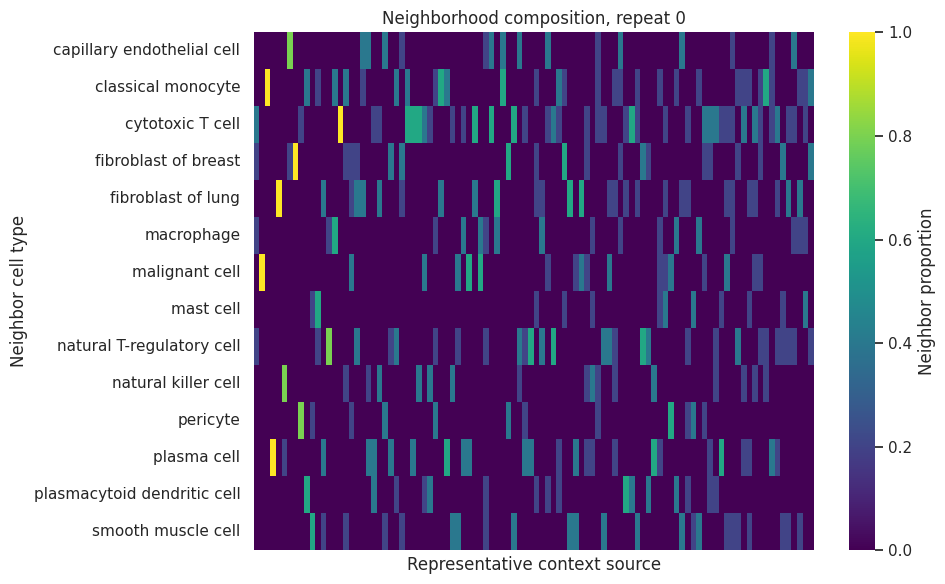

In [344]:
# Show unique representative contexts from one repeat.
context_rows = selected.loc[(selected['sampling_repeat'] == repeats[0]) & selected['is_representative_context']]
context_rows = context_rows.drop_duplicates('context_source_cell_id').head(100)
context_plot = composition.iloc[context_rows['row_position'].to_numpy()].copy()
context_plot.index = context_rows['context_source_cell_id'].to_numpy()
active_types = context_plot.columns[context_plot.max(axis=0) > 0]
if len(context_plot) and len(active_types):
    fig, ax = plt.subplots(figsize=(max(7, len(active_types) * 0.7), 6))
    sns.heatmap(context_plot[active_types].T, cmap='viridis', vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'Neighbor proportion'})
    ax.set(xlabel='Representative context source', ylabel='Neighbor cell type', title=f'Neighborhood composition, repeat {repeats[0]}')
    ax.set_xticks([])
    plt.tight_layout()
    plt.show()
else:
    print('No representative contexts to plot')

In [345]:
# GENES = list(adata.var.sort_values(by='Annotation_DB').groupby('Annotation_DB')['feature_name'].head(n=5).values)

# Keep the first occurrence of each unique cell_id
# adata.obs_names = adata.obs_names.astype(str)
# adata = adata.to_memory()
adata.obs_names = adata.obs_names.astype(str)
adata.var_names = adata.var_names.astype(str)
mask = list(~adata.obs['cell_id'].duplicated(keep='first').values)

adata_unique = adata[mask].copy()
adata_unique
# adata.obs.index

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 3236 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'focal_cell_id', 'context_source_cell_id', 'context_kind', 'is_original', 'is_representative_context', 'sampling_repeat', 'context_number', 'split', 'tissue'
    var: 'feature_name', 'feature_type', 'genome', 'id', 'name', 'feature', 'Genes', 'Ensembl_ID', 'Num_Probesets', 'Co

In [346]:
adata_unique.var = adata_unique.var.set_index('feature_name')
adata_unique.var['feature_name'] = adata_unique.var_names

In [ ]:
superclass_map = {
    "NK cell": "T/NK",
    "canonical T cell marker": "T/NK",

    "B cell": "B/plasma",
    "plasma cell": "B/plasma",

    "dendritic cell": "Myeloid",
    "macrophage": "Myeloid",
    "monocyte": "Myeloid",
    "myeloid cell": "Myeloid",
    "mast cell": "Myeloid",

    "epithelial cell": "Epithelial/malignant",
    "malignant cell": "Epithelial/malignant",

    "fibroblast": "Stromal",
    "smooth muscle cell": "Stromal",
    "adipocyte": "Stromal",

    "endothelial cell": "Endothelial",

    "immune cell": "Immune",
}

In [370]:
adata_unique.var['Annotation_superclass'] = adata_unique.var['Annotation_DB'].map(superclass_map)

In [371]:
adata_unique.var

,feature_type,genome,id,name,feature,Genes,Ensembl_ID,Num_Probesets,Codewords,Annotation,Annotation_DB,feature_name,num_expressed,mean_expression,Annotation_superclass
feature_name,,,,,,,,,,,,,,,
CD79B,Gene Expression,Unknown,ENSG00000007312,CD79B,CD79B,CD79B,ENSG00000007312,5,1,B cells,B cell,CD79B,79,0.024722,B/plasma
SLAMF7,Gene Expression,Unknown,ENSG00000026751,SLAMF7,SLAMF7,SLAMF7,ENSG00000026751,8,1,B cells,B cell,SLAMF7,624,0.258035,B/plasma
FAM107B,Gene Expression,Unknown,ENSG00000065809,FAM107B,FAM107B,FAM107B,ENSG00000065809,8,1,B cells,B cell,FAM107B,2269,1.419963,B/plasma
TCL1A,Gene Expression,Unknown,ENSG00000100721,TCL1A,TCL1A,TCL1A,ENSG00000100721,7,1,B cells,B cell,TCL1A,21,0.006489,B/plasma
CD79A,Gene Expression,Unknown,ENSG00000105369,CD79A,CD79A,CD79A,ENSG00000105369,3,1,B cells,B cell,CD79A,146,0.053461,B/plasma
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LARS,Gene Expression,Unknown,ENSG00000133706,LARS,LARS,LARS,ENSG00000133706,8,1,Smooth muscle cells,smooth muscle cell,LARS,895,0.337454,Stromal
AVPR1A,Gene Expression,Unknown,ENSG00000166148,AVPR1A,AVPR1A,AVPR1A,ENSG00000166148,8,1,Smooth muscle cells,smooth muscle cell,AVPR1A,30,0.009580,Stromal
THAP2,Gene Expression,Unknown,ENSG00000173451,THAP2,THAP2,THAP2,ENSG00000173451,8,1,Smooth muscle cells,smooth muscle cell,THAP2,160,0.050989,Stromal


In [374]:
adata_unique.X

<3236x277 sparse matrix of type '<class 'numpy.int32'>'
	with 148581 stored elements in Compressed Sparse Row format>

In [375]:
import numpy as np

k = 20
n = 2

adata_unique.var["num_expressed"] = np.asarray(
    (adata_unique.X > 0).sum(axis=0)
).ravel()

adata_unique.var["mean_expression"] = np.asarray(
    adata_unique.X.sum(axis=0) / (adata_unique.X>0).sum(axis=0)
).ravel()

eligible = adata_unique.var.loc[
    adata_unique.var["num_expressed"] >= k
].copy()

GENES = (
    eligible
    .sort_values(
        ["Annotation_superclass", "mean_expression"],
        ascending=[True, False],
    )
    .groupby("Annotation_superclass", observed=True)
    .head(4)["feature_name"]
    .tolist()
)

In [376]:
GENES

['FAM107B',
 'ERN1',
 'ITM2C',
 'SEC11C',
 'WARS',
 'AQP1',
 'PECAM1',
 'VWF',
 'SERHL2',
 'KRT7',
 'CXCL12',
 'TOMM7',
 'PTPRC',
 'LYZ',
 'IL2RG',
 'APOC1',
 'CD68',
 'SFRP4',
 'LUM',
 'POSTN',
 'CCDC80',
 'IL7R',
 'CXCR4',
 'CD3E',
 'TRAC']

In [377]:
gene_info = adata_unique.var.sort_values(by=['Annotation','num_expressed'],ascending=[True,False]).groupby('Annotation').head(n=2)

In [378]:
gene_info

,feature_type,genome,id,name,feature,Genes,Ensembl_ID,Num_Probesets,Codewords,Annotation,Annotation_DB,feature_name,num_expressed,mean_expression,Annotation_superclass
feature_name,,,,,,,,,,,,,,,
PDE4A,Gene Expression,Unknown,ENSG00000065989,PDE4A,PDE4A,PDE4A,ENSG00000065989,7,1,Adipocytes,adipocyte,PDE4A,291,1.092784,Stromal
PDCD1LG2,Gene Expression,Unknown,ENSG00000197646,PDCD1LG2,PDCD1LG2,PDCD1LG2,ENSG00000197646,8,1,Adipocytes,adipocyte,PDCD1LG2,138,1.072464,Stromal
FAM107B,Gene Expression,Unknown,ENSG00000065809,FAM107B,FAM107B,FAM107B,ENSG00000065809,8,1,B cells,B cell,FAM107B,2269,2.025121,B/plasma
ERN1,Gene Expression,Unknown,ENSG00000178607,ERN1,ERN1,ERN1,ENSG00000178607,8,1,B cells,B cell,ERN1,1690,1.760355,B/plasma
S100A4,Gene Expression,Unknown,ENSG00000196154,S100A4,S100A4,S100A4,ENSG00000196154,4,1,Breast cancer,malignant cell,S100A4,1806,1.806202,Epithelial/malignant
CXCL12,Gene Expression,Unknown,ENSG00000107562,CXCL12,CXCL12,CXCL12,ENSG00000107562,8,1,Breast cancer,malignant cell,CXCL12,1792,2.380022,Epithelial/malignant
TOMM7,Gene Expression,Unknown,ENSG00000196683,TOMM7,TOMM7,TOMM7,ENSG00000196683,7,1,Breast glandular cells,epithelial cell,TOMM7,2174,1.965041,Epithelial/malignant
TPD52,Gene Expression,Unknown,ENSG00000076554,TPD52,TPD52,TPD52,ENSG00000076554,8,1,Breast glandular cells,epithelial cell,TPD52,995,1.410050,Epithelial/malignant
GLIPR1,Gene Expression,Unknown,ENSG00000139278,GLIPR1,GLIPR1,GLIPR1,ENSG00000139278,8,1,Breast myoepithelial cells,epithelial cell,GLIPR1,1368,1.463450,Epithelial/malignant


In [379]:
adata.var = adata.var.set_index('feature_name')

KeyError: "None of ['feature_name'] are in the columns"

## Changes from the original neighborhood

The baseline is paired by both query cell and repeat. Each pair must have exactly one original row.

In [380]:
gene_labels = (adata.var['feature_name'].fillna('').astype(str).to_numpy()
               if 'feature_name' in adata.var else adata.var_names.astype(str).to_numpy())
gene_labels = np.where(gene_labels == '', adata.var_names.astype(str).to_numpy(), gene_labels)
Y = dense_rows(adata.layers[PROB_LAYER], selected_positions).astype(np.float32)
if GENES:
    wanted = set(GENES)
    gene_idx = np.flatnonzero(np.isin(gene_labels, list(wanted)) | np.isin(adata.var_names.astype(str), list(wanted)))
    if not len(gene_idx):
        raise ValueError(f'No requested genes found: {GENES}')
else:
    representative = selected['is_representative_context'].to_numpy()
    if not representative.any():
        representative = np.ones(len(selected), dtype=bool)
    gene_idx = np.argsort(np.nanvar(Y[representative], axis=0))[-min(N_AUTO_GENES, adata.n_vars):][::-1]
gene_names = gene_labels[gene_idx]
print('Selected genes:', ', '.join(gene_names))

keys = ['focal_cell_id', 'sampling_repeat']
original = selected.loc[selected['is_original'], keys].copy()
original['local_position'] = np.flatnonzero(selected['is_original'].to_numpy())
if original.duplicated(keys).any():
    raise ValueError('Multiple original rows for a query and repeat')
baseline = selected[keys].reset_index(drop=True).merge(original, on=keys, how='left', validate='many_to_one')['local_position']
if baseline.isna().any():
    raise ValueError('At least one query/repeat has no original row')
baseline_idx = baseline.to_numpy(dtype=int)
delta = Y[:, gene_idx] - Y[baseline_idx][:, gene_idx]
original_expression = dense_rows(adata.X, selected_positions[original['local_position'].to_numpy()])[:, gene_idx]
expressed_at_original = np.zeros((len(selected), len(gene_idx)), dtype=bool)
expressed_at_original[original['local_position'].to_numpy()] = original_expression > 0
expressed = expressed_at_original[baseline_idx]
expressed_by_group = {(str(row.focal_cell_id), int(row.sampling_repeat)): expressed_at_original[int(row.local_position)]
                      for row in original.itertuples(index=False)}

long = selected[keys + ['context_source_cell_id', 'is_original', 'is_representative_context']].reset_index(drop=True)
long = long.loc[long.index.repeat(len(gene_idx))].reset_index(drop=True)
long['gene'] = np.tile(gene_names, len(selected))
long['probability'] = Y[:, gene_idx].reshape(-1)
long['delta_from_original'] = delta.reshape(-1)
long['expressed_at_original'] = expressed.reshape(-1)
display(long.head())

Selected genes: FAM107B, ITM2C, SEC11C, ERN1, CXCR4, IL7R, CD3E, TRAC, IL2RG, VWF, WARS, AQP1, PECAM1, SERHL2, TOMM7, CCDC80, SFRP4, POSTN, LUM, PTPRC, LYZ, CD68, APOC1, CXCL12, KRT7


,focal_cell_id,sampling_repeat,context_source_cell_id,is_original,is_representative_context,gene,probability,delta_from_original,expressed_at_original
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,False,True,FAM107B,0.0,0.0,False
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,False,True,ITM2C,0.0,0.0,False
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,False,True,SEC11C,0.0,0.0,False
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,False,True,ERN1,0.0,0.0,False
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,False,True,CXCR4,0.0,0.0,False


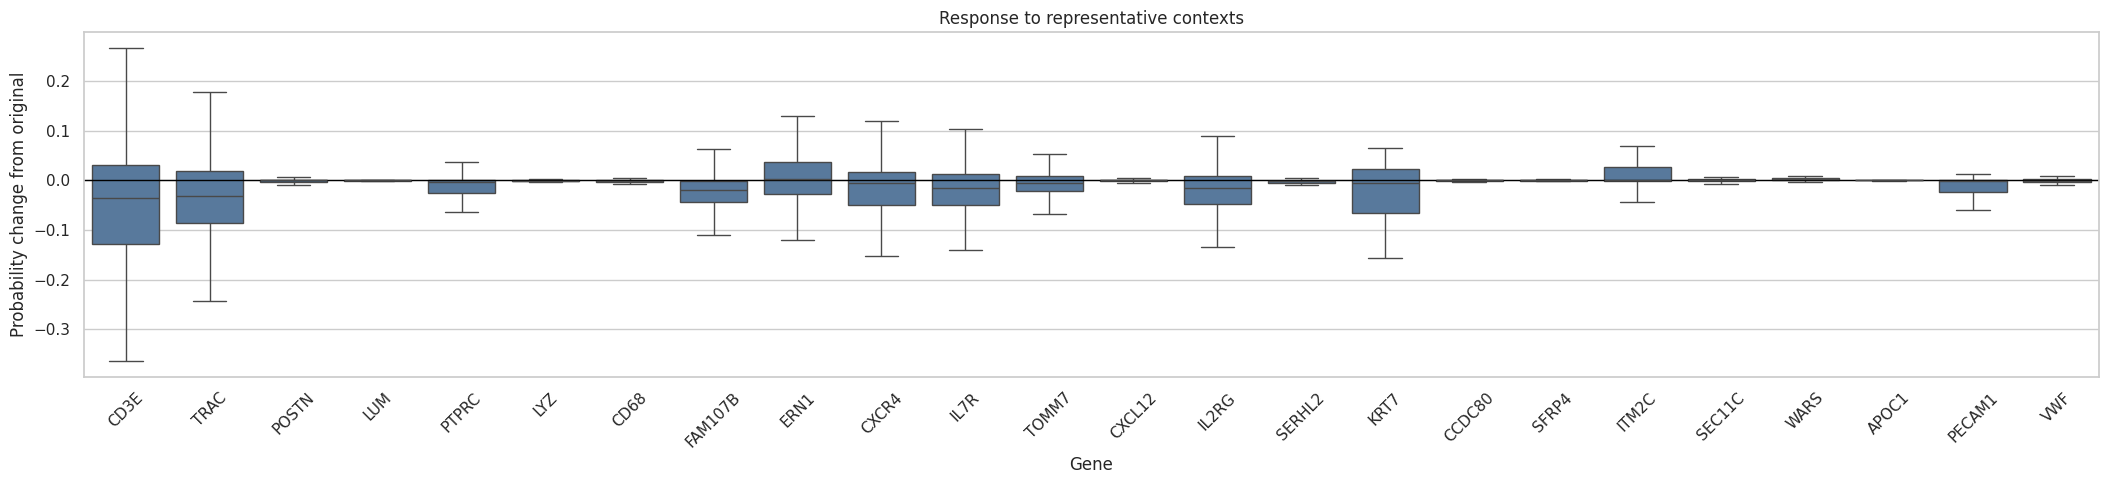

In [381]:
plot_data = long.loc[long['is_representative_context'] & ~long['is_original'] & long['expressed_at_original']]
if len(plot_data):
    fig, ax = plt.subplots(figsize=(max(8, len(gene_names) * 0.85), 5))
    sns.boxplot(data=plot_data, x='gene', y='delta_from_original', showfliers=False, color='#4C78A8', ax=ax)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel='Gene', ylabel='Probability change from original', title='Response to representative contexts')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print('No non-original representative contexts to plot')

## Neighborhood composition associations

For each query and repeat, fit a separate one-variable slope for each neighbor cell type using representative contexts. The plotted value is the estimated probability change for a 10 percentage-point increase in that type's neighborhood share.

In [382]:
def estimate_slopes(selected, composition, gene_probabilities, gene_names, expressed_by_group):
    records = []
    representative = selected['is_representative_context'].to_numpy()
    source_ids = selected['context_source_cell_id'].to_numpy()
    for (focal_id, repeat), positions in selected.groupby(['focal_cell_id', 'sampling_repeat'], observed=True).indices.items():
        positions = np.asarray(positions, dtype=int)
        positions = positions[representative[positions]]
        _, first = np.unique(source_ids[positions], return_index=True)
        positions = positions[np.sort(first)]
        if len(positions) < MIN_CONTEXTS:
            continue
        X = composition.iloc[positions].to_numpy(dtype=np.float32)
        P = gene_probabilities[positions]
        valid = np.isfinite(X).all(axis=1) & np.isfinite(P).all(axis=1)
        X, P = X[valid], P[valid]
        if len(X) < MIN_CONTEXTS:
            continue
        Xc, Pc = X - X.mean(axis=0), P - P.mean(axis=0)
        denominator = (Xc ** 2).sum(axis=0)
        eligible = (denominator > 1e-10) & ((X > 0).mean(axis=0) >= MIN_PREVALENCE)
        for j in np.flatnonzero(eligible):
            slopes = 0.1 * (Xc[:, j] @ Pc) / denominator[j]
            expression_mask = expressed_by_group[(str(focal_id), int(repeat))]
            records.extend((str(focal_id), int(repeat), str(composition.columns[j]), str(gene), float(slope), len(X))
                           for gene, slope, is_expressed in zip(gene_names, slopes, expression_mask) if is_expressed)
    return pd.DataFrame(records, columns=['focal_cell_id', 'sampling_repeat', 'neighbor_cell_type', 'gene', 'delta_p_per_10pct', 'n_contexts'])

slopes = estimate_slopes(selected, C, Y[:, gene_idx], gene_names, expressed_by_group)
print(f'{len(slopes):,} slope estimates from {slopes["focal_cell_id"].nunique()} query cells')
display(slopes.head())

3,262 slope estimates from 19 query cells


,focal_cell_id,sampling_repeat,neighbor_cell_type,gene,delta_p_per_10pct,n_contexts
0,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,1,capillary endothelial cell,FAM107B,-0.006154,200
1,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,1,capillary endothelial cell,ERN1,-0.016573,200
2,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,1,capillary endothelial cell,CXCR4,-0.002056,200
3,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,1,capillary endothelial cell,IL7R,0.012932,200
4,GSM9509172_breast_breast_B1_B1_1_rctd_annotate...,1,capillary endothelial cell,CD3E,-0.016386,200


In [383]:
gene_names

array(['FAM107B', 'ITM2C', 'SEC11C', 'ERN1', 'CXCR4', 'IL7R', 'CD3E',
       'TRAC', 'IL2RG', 'VWF', 'WARS', 'AQP1', 'PECAM1', 'SERHL2',
       'TOMM7', 'CCDC80', 'SFRP4', 'POSTN', 'LUM', 'PTPRC', 'LYZ', 'CD68',
       'APOC1', 'CXCL12', 'KRT7'], dtype=object)

In [384]:
slopes['gene'] = pd.Categorical(slopes['gene'],categories=GENES,ordered=True)


In [385]:
slopes['Annotation_DB'].unique()


KeyError: 'Annotation_DB'

In [386]:
gene_info

,feature_type,genome,id,name,feature,Genes,Ensembl_ID,Num_Probesets,Codewords,Annotation,Annotation_DB,feature_name,num_expressed,mean_expression,Annotation_superclass
feature_name,,,,,,,,,,,,,,,
PDE4A,Gene Expression,Unknown,ENSG00000065989,PDE4A,PDE4A,PDE4A,ENSG00000065989,7,1,Adipocytes,adipocyte,PDE4A,291,1.092784,Stromal
PDCD1LG2,Gene Expression,Unknown,ENSG00000197646,PDCD1LG2,PDCD1LG2,PDCD1LG2,ENSG00000197646,8,1,Adipocytes,adipocyte,PDCD1LG2,138,1.072464,Stromal
FAM107B,Gene Expression,Unknown,ENSG00000065809,FAM107B,FAM107B,FAM107B,ENSG00000065809,8,1,B cells,B cell,FAM107B,2269,2.025121,B/plasma
ERN1,Gene Expression,Unknown,ENSG00000178607,ERN1,ERN1,ERN1,ENSG00000178607,8,1,B cells,B cell,ERN1,1690,1.760355,B/plasma
S100A4,Gene Expression,Unknown,ENSG00000196154,S100A4,S100A4,S100A4,ENSG00000196154,4,1,Breast cancer,malignant cell,S100A4,1806,1.806202,Epithelial/malignant
CXCL12,Gene Expression,Unknown,ENSG00000107562,CXCL12,CXCL12,CXCL12,ENSG00000107562,8,1,Breast cancer,malignant cell,CXCL12,1792,2.380022,Epithelial/malignant
TOMM7,Gene Expression,Unknown,ENSG00000196683,TOMM7,TOMM7,TOMM7,ENSG00000196683,7,1,Breast glandular cells,epithelial cell,TOMM7,2174,1.965041,Epithelial/malignant
TPD52,Gene Expression,Unknown,ENSG00000076554,TPD52,TPD52,TPD52,ENSG00000076554,8,1,Breast glandular cells,epithelial cell,TPD52,995,1.410050,Epithelial/malignant
GLIPR1,Gene Expression,Unknown,ENSG00000139278,GLIPR1,GLIPR1,GLIPR1,ENSG00000139278,8,1,Breast myoepithelial cells,epithelial cell,GLIPR1,1368,1.463450,Epithelial/malignant


In [387]:
slopes = slopes.merge(gene_info.reset_index(drop=True)[['feature_name','Ensembl_ID','Annotation','Annotation_DB']],left_on='gene',right_on='feature_name',how='left')

In [388]:
slopes['Annotation_coarse'] = slopes['Annotation_DB'].map(superclass_map)

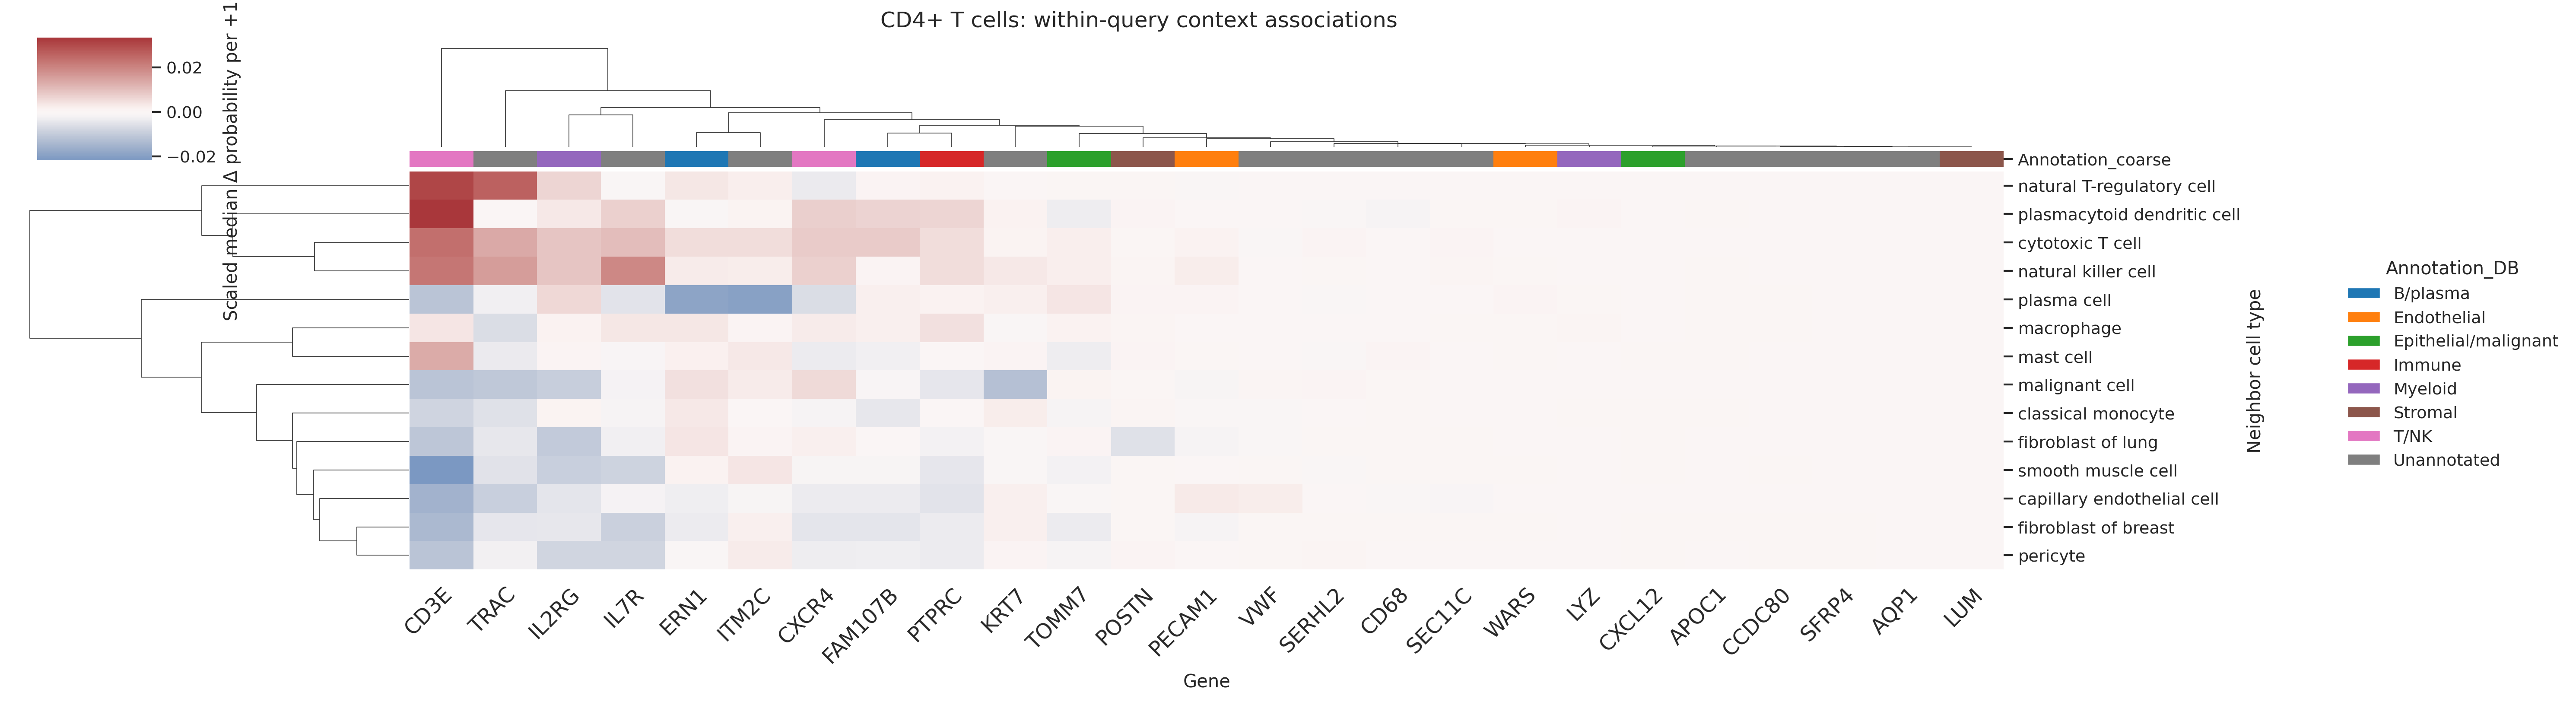

In [391]:
from matplotlib.patches import Patch

if len(slopes):
    summary = (
        slopes.groupby(["neighbor_cell_type", "gene"], observed=True)
        ["delta_p_per_10pct"].median()
    )
    heatmap = summary.unstack("gene")
    heatmap = heatmap.reindex(columns=GENES if GENES else gene_names)

    # scale = heatmap.abs().max(axis=0).replace(0, np.nan)
    # heatmap = heatmap.div(scale, axis=1).fillna(0)
    heatmap = heatmap.fillna(0)

    # Each gene should have one Annotation_DB value.
    gene_annotations = slopes[["gene", "Annotation_coarse"]].drop_duplicates()
    if gene_annotations["gene"].duplicated().any():
        raise ValueError("Some genes have multiple Annotation_DB values")

    annotation = (
        gene_annotations.set_index("gene")["Annotation_coarse"]
        .reindex(heatmap.columns)
        .fillna("Unannotated")
        .astype(str)
    )

    categories = sorted(annotation.unique())
    palette = sns.color_palette("tab10", n_colors=len(categories))
    color_map = dict(zip(categories, palette))
    column_colors = annotation.map(color_map)

    g = sns.clustermap(
        heatmap,
        col_colors=column_colors,
        cmap="vlag",
        center=0,
        # vmin=-1,
        # vmax=1,
        metric="euclidean",
        method="average",
        figsize=(max(8, len(heatmap.columns) * 0.85),
                 max(5, len(heatmap) * 0.45)),
        cbar_kws={"label": "Scaled median Δ probability per +10% neighbors"},
    )
    g.ax_heatmap.tick_params(axis="x", labelsize=14)
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    g.fig.set_dpi(250)
    g.ax_heatmap.set_xlabel("Gene")
    g.ax_heatmap.set_ylabel("Neighbor cell type")
    g.ax_heatmap.tick_params(axis="x", labelsize=14, rotation=45)
    g.fig.suptitle("CD4+ T cells: within-query context associations", y=1.02)

    handles = [
        Patch(facecolor=color_map[name], label=name)
        for name in categories
    ]
    g.fig.legend(
        handles=handles,
        title="Annotation_DB",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
    )
    plt.show()
else:
    print("No eligible slopes; reduce MIN_CONTEXTS or MIN_PREVALENCE")

In [ ]:
gene_info

,feature_name,feature_type,genome,id,name,feature,Genes,Ensembl_ID,Num_Probesets,Codewords,Annotation,Annotation_DB,num_expressed
189,PDE4A,Gene Expression,Unknown,ENSG00000065989,PDE4A,PDE4A,PDE4A,ENSG00000065989,7,1,Adipocytes,adipocyte,93
153,LPL,Gene Expression,Unknown,ENSG00000175445,LPL,LPL,LPL,ENSG00000175445,8,1,Adipocytes,adipocyte,45
209,RAMP2,Gene Expression,Unknown,ENSG00000131477,RAMP2,RAMP2,RAMP2,ENSG00000131477,4,1,Adipocytes,adipocyte,40
98,FAM107B,Gene Expression,Unknown,ENSG00000065809,FAM107B,FAM107B,FAM107B,ENSG00000065809,8,1,B cells,B cell,691
95,ERN1,Gene Expression,Unknown,ENSG00000178607,ERN1,ERN1,ERN1,ENSG00000178607,8,1,B cells,B cell,515
132,ITM2C,Gene Expression,Unknown,ENSG00000135916,ITM2C,ITM2C,ITM2C,ENSG00000135916,6,1,B cells,B cell,373
74,CXCL12,Gene Expression,Unknown,ENSG00000107562,CXCL12,CXCL12,CXCL12,ENSG00000107562,8,1,Breast cancer,malignant cell,567
216,S100A4,Gene Expression,Unknown,ENSG00000196154,S100A4,S100A4,S100A4,ENSG00000196154,4,1,Breast cancer,malignant cell,551
150,LDHB,Gene Expression,Unknown,ENSG00000111716,LDHB,LDHB,LDHB,ENSG00000111716,8,1,Breast cancer,malignant cell,496
260,TOMM7,Gene Expression,Unknown,ENSG00000196683,TOMM7,TOMM7,TOMM7,ENSG00000196683,7,1,Breast glandular cells,epithelial cell,690


In [187]:
slopes['neighbor_cell_type'].unique()

array(['capillary endothelial cell', 'classical monocyte',
       'cytotoxic T cell', 'fibroblast of breast', 'fibroblast of lung',
       'macrophage', 'malignant cell', 'mast cell',
       'natural T-regulatory cell', 'natural killer cell', 'pericyte',
       'plasma cell', 'plasmacytoid dendritic cell', 'smooth muscle cell'],
      dtype=object)

In [183]:
gene_info[gene_info['Annotation'].isin(adata.obs['harmony_cell_type'].unique())]

,feature_name,feature_type,genome,id,name,feature,Genes,Ensembl_ID,Num_Probesets,Codewords,Annotation,Annotation_DB,num_expressed


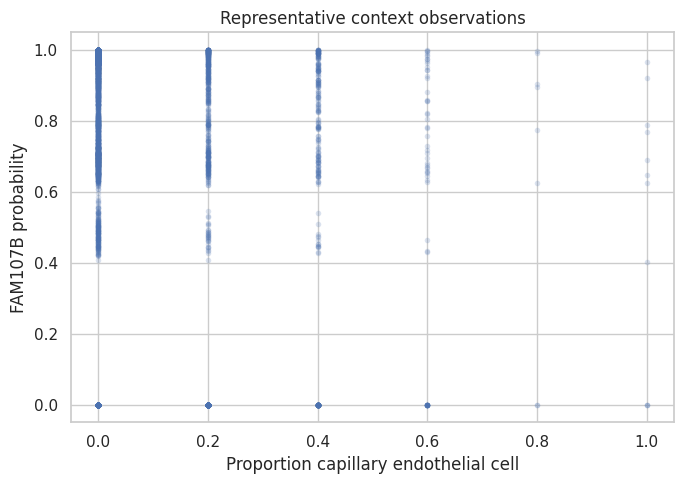

In [369]:
# Plot one gene against one neighbor proportion, retaining query identity in the data.
if len(slopes):
    plot_gene = str(gene_names[0])
    plot_type = str(slopes.loc[slopes['gene'] == plot_gene, 'neighbor_cell_type'].value_counts().index[0])
    mask = selected['is_representative_context'].to_numpy()
    scatter = pd.DataFrame({'neighbor_proportion': C[plot_type].to_numpy()[mask],
                            'probability': Y[:, gene_idx[0]][mask]})
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.scatterplot(data=scatter.sample(min(5000, len(scatter)), random_state=RANDOM_SEED),
                    x='neighbor_proportion', y='probability', alpha=0.2, s=16, linewidth=0, ax=ax)
    ax.set(xlabel=f'Proportion {plot_type}', ylabel=f'{plot_gene} probability', title='Representative context observations')
    plt.tight_layout()
    plt.show()

For a full run, set `MAX_FOCAL_CELLS = None` and `MAX_REPEATS = None`. This can use several GB of memory. Close the backed input afterward with `adata.file.close()`.